# Шаг 2. Самая простая языковая модель: биграммы

**Языковая модель** — это программа, которая по началу текста угадывает, что будет дальше.
Самый простой вариант — **биграмма**: смотрим только на **одну** предыдущую букву.

Возьмём список русских имён (`names.txt`) и посчитаем, сколько раз за каждой буквой шла каждая другая буква.
К каждому имени по краям припишем точку: `.анна.` — так модель узнает, с каких букв имена начинаются и на какие заканчиваются.

**Структура примера (алгоритм):**
1. Строим словарь символов имён (точка + буквы).
2. Разбираем все имена на пары «буква → следующая».
3. Заполняем таблицу подсчётов `N[текущая, следующая]` и рисуем её.
4. Делим каждую строку на её сумму — получаем вероятности; проверяем их «нечестным кубиком».
5. Придумываем новые имена: начинаем с точки и тянем буквы по вероятностям, пока не выпадет точка.
6. Считаем вероятность целого имени и учимся оценивать имена «штрафом».
7. Считаем **loss** — насколько хорошо модель угадывает следующую букву во всех именах.

In [ ]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session01–session05 и dataset).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session05")  # здесь лежит common.py и сохраняются результаты
    sys.path.insert(0, os.getcwd())

## Общий модуль `common.py`

Во всех примерах сессии используется модуль `common.py` из этой же папки:

| Имя | Что делает |
|-----|------------|
| `load_names()`, `load_text()` | русские имена из `names.txt` и «Евгений Онегин» (главы 1–8) из `onegin.txt` |
| `CharTokenizer(text)` | словарь символов: `encode` — строка → номера, `decode` — номера → строка, `vocab_size` — размер словаря |
| `name_tokenizer`, `bigram_pairs`, `bigram_counts` | словарь для имён (точка `.` — начало/конец имени), пары «буква → следующая», таблица подсчётов |
| `sample_name(probs, tok)` | придумать имя по таблице вероятностей |
| `apply_temperature(logits, T)` | вероятности из «сырых оценок» с температурой T |
| `MiniGPT`, `Block`, `SelfAttention` | маленький трансформер по символам |
| `save_gpt`, `load_gpt` | сохранить / загрузить GPT вместе со словарём |
| `load_session04()` | модуль `common.py` из сессии 4 (кошки и собаки, `SimpleCNN`) — для бонуса |
| `show()` | показать графики matplotlib |

> Запускайте примеры из папки `session05`, иначе `import common` не найдёт модуль.
> Библиотеки: `pip install -r requirements.txt`. Тексты лежат в этой же папке, интернет не нужен.

## 1. Пары букв

`bigram_pairs` возвращает два тензора номеров: `x` — текущая буква, `y` — следующая. Из «анна» получается пять пар:
`.а`, `ан`, `нн`, `на`, `а.` — первая пара говорит «имя начинается на а», последняя — «имя кончается на а».

In [1]:
import matplotlib.pyplot as plt
import torch

from common import BOUNDARY, bigram_counts, bigram_pairs, load_names, name_tokenizer, sample_name, show

names = load_names()
print("Имён:", len(names), "— например:", names[:8])
tok = name_tokenizer(names)
print("Символов в словаре (точка + буквы):", tok.vocab_size, repr("".join(tok.chars)))

xs, ys = bigram_pairs(names, tok)
print("Пар «буква → следующая»:", len(xs))
print("Пары из имени «анна»:", [tok.decode([x]) + tok.decode([y]) for x, y in zip(*bigram_pairs(["анна"], tok))])

counts = bigram_counts(names, tok)
print("Чаще всего имя начинается на:", [tok.itos[i] for i in counts[0].argsort(descending=True)[:5].tolist()])
print("Чаще всего имя заканчивается на:", [tok.itos[i] for i in counts[:, 0].argsort(descending=True)[:5].tolist()])

Имён: 199 — например: ['александр', 'алексей', 'анатолий', 'андрей', 'антон', 'аркадий', 'арсений', 'артём']
Символов в словаре (точка + буквы): 29 '.абвгдежзийклмнопрстуфхчьэюяё'
Пар «буква → следующая»: 1403
Пары из имени «анна»: ['.а', 'ан', 'нн', 'на', 'а.']
Чаще всего имя начинается на: ['а', 'в', 'м', 'с', 'е']
Чаще всего имя заканчивается на: ['а', 'я', 'й', 'н', 'р']


## 2. Таблица подсчётов

Строка — текущая буква, столбец — следующая. Чем темнее клетка, тем чаще такая пара.
Первая строка (точка) — с чего начинаются имена, первый столбец — чем заканчиваются (видно, что часто на «а» и «й»).
Эта таблица — **вся** модель: больше она ничего не знает.

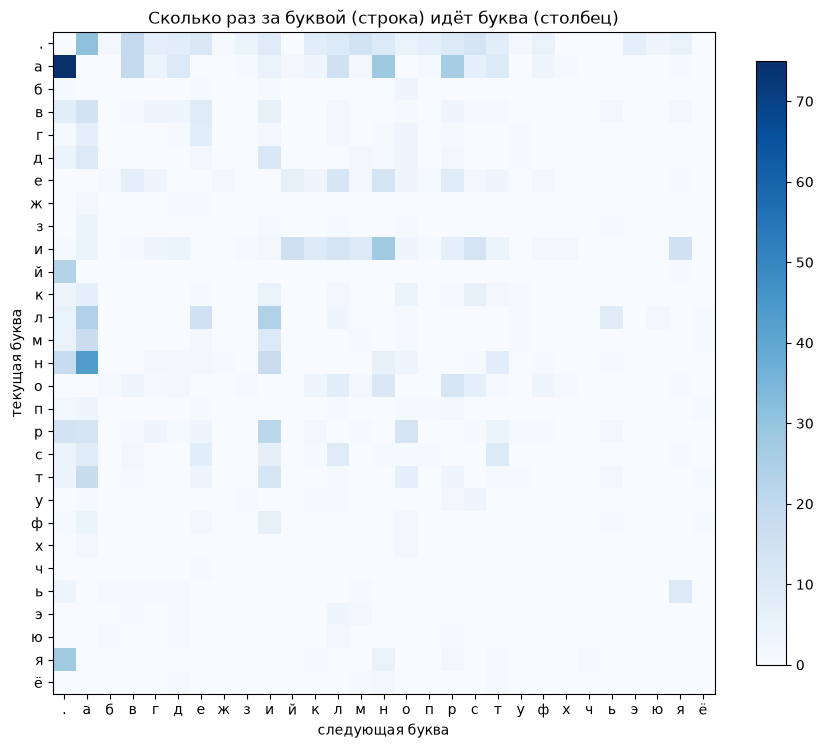

In [2]:
plt.figure(figsize=(9, 8))
plt.imshow(counts, cmap="Blues")
plt.xticks(range(tok.vocab_size), tok.chars)
plt.yticks(range(tok.vocab_size), tok.chars)
plt.xlabel("следующая буква")
plt.ylabel("текущая буква")
plt.title("Сколько раз за буквой (строка) идёт буква (столбец)")
plt.colorbar(shrink=0.8)
plt.tight_layout()
plt.savefig("bigram_counts.png", dpi=100)
show()

## 3. Подсчёты → вероятности

Делим каждую строку на её сумму — получаем вероятности: в каждой строке они в сумме дают 1.
Например, после «а» в 35% случаев имя заканчивается (точка), в 13% идёт «н».

**Сглаживание** `+ 0.1`: пара, которой не было в наших 199 именах, получит маленькую, но не нулевую вероятность.
Иначе модель была бы «абсолютно уверена», что такое имя невозможно — а это неправда, просто нам не попалось.

In [3]:
# Подсчёты → вероятности: каждую строку делим на её сумму.
# +0.1 ко всем клеткам («сглаживание»): иначе невиданная пара получит вероятность ровно 0.
probs = (counts + 0.1) / (counts + 0.1).sum(dim=1, keepdim=True)
print("После «а» чаще всего идут:",
      [(tok.itos[i], round(probs[tok.stoi['а'], i].item(), 3)) for i in probs[tok.stoi["а"]].argsort(descending=True)[:5].tolist()])

После «а» чаще всего идут: [('.', 0.348), ('н', 0.13), ('р', 0.121), ('в', 0.088), ('л', 0.07)]


### Нечестный кубик

`torch.multinomial(probs, n)` — «бросить нечестный кубик» n раз: выбрать номер с заданными вероятностями.
Бросим его 1000 раз для первой буквы имени и посчитаем, какая доля бросков выпала на каждую букву.
Доли получаются **близкими** к вероятностям, но не равными — это случайность. Чем больше бросков, тем ближе.

In [4]:
# «Нечестный кубик»: 1000 раз выбираем первую букву имени и сравниваем частоты с вероятностями
g = torch.Generator().manual_seed(0)
rolls = torch.multinomial(probs[0], 1000, replacement=True, generator=g)
print("Первая буква: вероятность в таблице → доля из 1000 бросков")
for i in probs[0].argsort(descending=True)[:5].tolist():
    print(f"  «{tok.itos[i]}»: {probs[0, i]:.3f} → {(rolls == i).float().mean():.3f}")

Первая буква: вероятность в таблице → доля из 1000 бросков
  «а»: 0.154 → 0.143
  «в»: 0.095 → 0.104
  «м»: 0.070 → 0.063
  «с»: 0.065 → 0.056
  «е»: 0.055 → 0.046


## 4. Придумываем имена

Начинаем с точки, бросаем кубик строки «.» — получаем первую букву; бросаем кубик строки этой буквы — вторую, и так пока не выпадет точка.

Имена получаются **похожими на русские** по звучанию, но странными: модель помнит только одну букву назад
и не знает, что имя уже длинное или что три гласные подряд — плохо. Зато по сравнению со случайными буквами — огромный шаг вперёд.

In [5]:
g = torch.Generator().manual_seed(1)
print("Придуманные имена:")
print(", ".join(sample_name(probs, tok, g) for _ in range(20)))

uniform = torch.ones_like(probs) / tok.vocab_size
print("А это буквы наугад, без всякой модели:")
print(", ".join(sample_name(uniform, tok, g) for _ in range(5)))

Придуманные имена:
а, ана, офьй, кодмидригдий, ю, са, вждийха, юбогерагарзин, верикия, саролланинаиянавег, вегерей, ияея, алас, вевафелюлиилья, дминтакслил, влий, я, мбория, аг, ветия
А это буквы наугад, без всякой модели:
срогза, ифйзгьлнюунмкрмфяхзн, юмрахзйпжокмгтхкьйхи, ёиейёвювбсежзуоийвэк, вгзвгдд


## 5. Вероятность целого имени

Модель умеет не только **писать** имена, но и **оценивать** их. Вероятность имени «анна» — это вероятность того, что
кубики выпадут ровно так: «а» после «.», потом «н» после «а» и так далее. Вероятности независимых событий **перемножаются**.

Смотрите, как быстро тает произведение: уже после пяти пар — сотые доли процента. Для текста из тысячи символов
получилось бы число, которое компьютер не может даже записать (оно округлится до нуля).
Выручает логарифм: **логарифм произведения = сумма логарифмов**. Складывать безопасно, а смысл тот же.

In [6]:
# Вероятность целого имени = произведение вероятностей всех его пар
ids = tok.encode(BOUNDARY + "анна" + BOUNDARY)
p_name = 1.0
for a, b in zip(ids, ids[1:]):
    p_name *= probs[a, b].item()
    print(f"P(«{tok.itos[b]}» после «{tok.itos[a]}») = {probs[a, b]:.3f}   произведение пока: {p_name:.6f}")
print("Произведения быстро становятся крошечными, поэтому вместо них складывают логарифмы:")
print(f"  log(произведение) = {torch.log(torch.tensor(p_name)):.3f}, "
      f"сумма логарифмов = {sum(probs[a, b].log().item() for a, b in zip(ids, ids[1:])):.3f}")

P(«а» после «.») = 0.154   произведение пока: 0.154037
P(«н» после «а») = 0.130   произведение пока: 0.020048
P(«н» после «н») = 0.057   произведение пока: 0.001133
P(«а» после «н») = 0.399   произведение пока: 0.000453
P(«.» после «а») = 0.348   произведение пока: 0.000157
Произведения быстро становятся крошечными, поэтому вместо них складывают логарифмы:
  log(произведение) = -8.756, сумма логарифмов = -8.756


### Штраф за имя

Средний `−log(вероятность)` по парам имени — это **штраф**: насколько модель «удивлена» таким именем.
Настоящие имена получают маленький штраф, а «ааааа» и «йьчх» — большой: таких пар модель почти не видела.
Так языковые модели могут отличать правдоподобный текст от бессмыслицы.

In [7]:
def name_loss(name):
    """Средний штраф модели на одном имени: чем меньше, тем «правдоподобнее» имя для биграммы."""
    x, y = bigram_pairs([name], tok)
    return -probs[x, y].log().mean().item()


for name in ["анна", "виталий", "ааааа", "йьчх"]:
    print(f"{name:>8}: штраф {name_loss(name):.2f} ({'есть' if name in names else 'нет'} в списке имён)")

    анна: штраф 1.75 (есть в списке имён)
 виталий: штраф 1.95 (есть в списке имён)
   ааааа: штраф 5.61 (нет в списке имён)
    йьчх: штраф 5.29 (нет в списке имён)


## 6. Loss всей модели

**Loss** — средний штраф `−log(вероятность правильной следующей буквы)` по **всем** парам всех имён — та самая *cross-entropy* из сессий 3–4.
Если модель уверенно угадывает, вероятность близка к 1, а штраф к 0. Угадывание наугад даёт `log(размер словаря)`:
у нас 29 символов, `log(29) ≈ 3.37`. Биграмма опускает штраф до ≈ 2.17 — это и есть мера того, сколько она выучила.

In [8]:
# Насколько модель хороша? Средний «штраф» −log(вероятность правильной следующей буквы).
# Это та же cross-entropy, что в сессиях 3–4: чем меньше, тем лучше модель угадывает.
loss = -probs[xs, ys].log().mean()
print(f"Средний штраф (loss) биграммной модели: {loss:.3f}")
print(f"Средний штраф угадывания наугад: {torch.log(torch.tensor(tok.vocab_size)):.3f}")

Средний штраф (loss) биграммной модели: 2.168
Средний штраф угадывания наугад: 3.367


## Попробуйте сами

1. Уберите сглаживание (`+ 0.1`). Что станет с loss? Почему он может стать бесконечным для нового имени? Проверьте на `name_loss("йьчх")`.
2. Бросьте «нечестный кубик» 100 и 100 000 раз. Насколько доли отличаются от вероятностей?
3. Посчитайте штраф для своего имени и имён одноклассников. Чьё имя биграмме кажется самым «русским»?
4. Добавьте в `names.txt` свои имена и посмотрите, как изменились придуманные имена.
5. Найдите в таблице самую частую пару букв. Совпадает ли она с вашей догадкой?
6. Как бы вы сделали **триграмму** — модель, которая смотрит на две предыдущие буквы? Сколько клеток будет в её таблице?